# Attention Mechanism Exploration

## What is attention mechanism?

To answer this question, let's start with some back story.

Back in 2014, researchers were working on text translation models. Word-by-word translation didn't work. They required contextual understanding and grammar alignment.

They were using a neural network with `encoder` and `decoder` submodules, in which `encoder` reads and processes the text, whereas `decoder` translates text. However, they discovered that a fixed length vector can hinder the understanding.

What if we let the model to reference to the original text to judge which part is the most useful? A word can attend to **multiple words** instead of one, with different emphasis. (This is called soft-search and soft-alignment)

This Neural Network architecture made the model SOTA at that time.

This was demonstrated in the 2014 paper [Neural Machine Translation by Jointly Learning to Align and Translate](https://arxiv.org/pdf/1409.0473)

Translations before `transformer` use `RNN(Recurrent Neural Network)` for the most popular encoder-decoder language translation architecture, which basically means output from the previous step is fed to current text to **update a hidden state** at each step with the upcoming new word. The model will use the final hidden state to generate translate sentence **one word at a time.**

There is certainly a problem here, you may have also spotted: Since RNN cannot directly access previous hidden state from the encoder during the training phase, **it relies only on current hidden state**. Therefore this leads to a **loss of context**, especially in complex sentences where dependencies might span long distances, like:

- *The **cat** that was sitting on the mat, which was next to the dog, **jumped.***

This is the beginning of `Attention Mechanism`, aka `Bahdanau Attention` named after one author of the paper.

Attention came to resolve this problem!

### Attention here means
<div class='alert alert-block alert-info'>
The mechanism's ability to compute attention weights by relating different positions in a single input sequence.
</div>

## 1. Simplified Attention Mechanism


Let's start by implementing a compact self attention python class, then to clarify every single component in this class.

In [1]:
import torch

inputs = torch.tensor(
  [[0.43, 0.15, 0.89], # Your     (x^1)
   [0.55, 0.87, 0.66], # journey  (x^2)
   [0.57, 0.85, 0.64], # starts   (x^3)
   [0.22, 0.58, 0.33], # with     (x^4)
   [0.77, 0.25, 0.10], # one      (x^5)
   [0.05, 0.80, 0.55]] # step     (x^6)
)

In [2]:
inputs.shape

torch.Size([6, 3])

In [3]:
inputs.shape[0] # Number of rows

6

In [4]:
inputs.shape[1] # Number of columns

3

- Each row represents a word.
- Each column represents an embedding dimension.

Here is the compact **self-attention** python class.

In [5]:
import torch.nn as nn

class SelfAttention_v1(nn.Module):
    def __init__(self, d_in, d_out):
        super().__init__()
        self.W_query = nn.Parameter(torch.rand(d_in, d_out))
        self.W_key   = nn.Parameter(torch.rand(d_in, d_out))
        self.W_value = nn.Parameter(torch.rand(d_in, d_out))
        # Initiating random Q,K,V matrices, which are going to be optimized

    def forward(self, x):
        keys = x @ self.W_key
        queries = x @ self.W_query
        values = x @ self.W_value
        # Resulting matrices = inputs * corresponding weight matrices
        # (6,3) * (3,2) => (6,2), (num_tokens, d_out)

        attn_scores = queries @ keys.T # (6,6)

        print(f"keys/queries/values.shape[1] (output dimensions):{keys.shape[1]}")
        print("For every query token, normalize its attention scores to other key tokens")

        attn_weights = torch.softmax(
            attn_scores / keys.shape[1]**0.5, dim=1 # Normalize each row
        )

        print(f"Attention Weights:\n{attn_weights}")
        print(f"The sum of each row of Attention Weight:\n{attn_weights.sum(dim=1)}")

        context_vec = attn_weights @ values # (6,6) * (6,2)
        return context_vec


We are going to use this coding scheme with PyTorch so frequently in the following parts.

- `__init__()` defines how many layers are in the model, or which parameters the model has.

- `forward()`, forward pass, defines what computation the input will pass through, and what returns at last.

In this PyTorch code, **SelfAttention_v1** is a class derived from **nn.Module**, which is a
**fundamental building block** of PyTorch models, providing necessary functionalities for
model layer creation and management.


The `__init__` method initializes trainable weight matrices `W_query`, `W_key`, and `W_value` for queries, keys, and values, each **transforming** the input dimension `d_in` to an
output dimension `d_out`.


During the forward pass, we compute the **attention scores**
(`attn_scores`) by multiplying queries and keys transposed($Q*K^{\top}$), **normalizing** these scores using the PyTorch version of `softmax`.

- Naive Softmax:
$\operatorname{softmax}(\mathbf{x})_i
= \frac{e^{x_i}}{\sum_{j=1}^{n} e^{x_j}}$

- PyTorch Softmax:
$\operatorname{softmax}(\mathbf{x})_i=
\frac{e^{x_i-m}}{\sum_{j=1}^{n}e^{x_j-m}},
\qquad m=\max_j x_j$

Finally, we create a **context vector** by weighting the values with these normalized attention
scores.


In [6]:
torch.manual_seed(123)
x_2 = inputs[1]         # Token 'Journey'
d_in = inputs.shape[1]
print(f"Input dimension: (inputs.shape[1]) {d_in}")
d_out = 2               # Output dimension
sa_v1 = SelfAttention_v1(d_in, d_out) # (6*3) * (3*2)
print(f"Context Vectors:\n{sa_v1(inputs)}")

Input dimension: (inputs.shape[1]) 3
keys/queries/values.shape[1] (output dimensions):2
For every query token, normalize its attention scores to other key tokens
Attention Weights:
tensor([[0.1551, 0.2104, 0.2059, 0.1413, 0.1074, 0.1799],
        [0.1500, 0.2264, 0.2199, 0.1311, 0.0906, 0.1820],
        [0.1503, 0.2256, 0.2192, 0.1315, 0.0914, 0.1819],
        [0.1591, 0.1994, 0.1962, 0.1477, 0.1206, 0.1769],
        [0.1610, 0.1949, 0.1923, 0.1501, 0.1265, 0.1752],
        [0.1557, 0.2092, 0.2048, 0.1419, 0.1089, 0.1794]],
       grad_fn=<SoftmaxBackward0>)
The sum of each row of Attention Weight:
tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000],
       grad_fn=<SumBackward1>)
Context Vectors:
tensor([[0.2996, 0.8053],
        [0.3061, 0.8210],
        [0.3058, 0.8203],
        [0.2948, 0.7939],
        [0.2927, 0.7891],
        [0.2990, 0.8040]], grad_fn=<MmBackward0>)


Good, now we are receiving a 6 * 2 tensor, which basically means there is 6 **samples**, while each sample has 2 **features**.
Since inputs contains six embedding vectors, we get a matrix storing the six
**context vectors**, as shown in the above result. 


We can improve the `SelfAttention_v1` implementation further by utilizing PyTorch's
`nn.Linear` layers, which effectively perform matrix multiplication when the bias units are
disabled. 


Additionally, a significant advantage of using `nn.Linear` instead of manually
implementing `nn.Parameter(torch.rand(...))` is that nn.Linear has an optimized **weight initialization** scheme, contributing to more stable and effective model training.

In [7]:
class SelfAttention_v2(nn.Module):
    def __init__(self, d_in, d_out, qkv_bias=False):
        super().__init__()
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)

    def forward(self, x):
        # The shape of x is going to be (batch_size, num_tokens, d_in) in the future
        # Then we have to use [-1] to refer to d_in, [-2] refer to num_tokens
        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)
        # We project the input into three different representations: keys, queries, and values. 
        print("Number of tokens", values.shape[-2])
        print("Number of output dimensions", values.shape[-1])
        print(f"Overall values shape of QKV matrices: {values.shape}")

        attn_scores = queries @ keys.T
        attn_weights = torch.softmax(attn_scores / keys.shape[1]**0.5, dim=1)

        context_vec = attn_weights @ values
        return context_vec


In [8]:
torch.manual_seed(123)
sa_v2 = SelfAttention_v2(d_in, d_out)
print(sa_v2(inputs))

Number of tokens 6
Number of output dimensions 2
Overall values shape of QKV matrices: torch.Size([6, 2])
tensor([[-0.5337, -0.1051],
        [-0.5323, -0.1080],
        [-0.5323, -0.1079],
        [-0.5297, -0.1076],
        [-0.5311, -0.1066],
        [-0.5299, -0.1081]], grad_fn=<MmBackward0>)


Note that `SelfAttention_v1` and `SelfAttention_v2` give different output trends because they
use **different initial weights** for the weight matrices.

Actually, ``nn.Linear`` uses a more
sophisticated weight initialization scheme.

### **Clarifications**

#### What are Query, Keys and Values?

- **Query** represents the current token that the model focuses on.
- **Key** are used to match with the query.
- **Value** represents the actual content or representation of the input items. Once the model determines which keys(which parts of the input) are most relavent to the query(current focus item), it retrives the corresponding values.

---

- **Imagine a library**:  
  - A **query** is the question you ask the librarian.  
  - A **key** is the index entry for each book.  
  - A **value** is the actual content inside each book.  
  You compare your question (query) to the index entries (keys) to decide which books (values) to read and how much attention to give each. 



#### What is projection here mean?

In ethis case, we initialted random `nn.Linear` layers for Q, K, and V, so when we use `keys = self.W_key(x)`, x is basically going through `y = x*W + b`, in which `x` is input vector, `W` is weight, while `b` is bias.

In this case, the argument in the `__init__` function has `qkv_bias` set to False.

#### Why we will use `-1` in later code? / Why don't just use `1` always? They represents the same dimension!

- `keys.shape[-1]` means the last dimension, which is the dimension of output vector.
- `dim=-1` means perfoming softmax at the last dimension.

So when we implement multihead attention later where the dimension could be more than 2-dimensions, this piece of code is still usable.

#### Why divide by `sqrt(dimension)` for the scaled dot product?

- `softmax()` is sensitive to magnitudes of its inputs. When the inputs are large, the differences between the exponential values of each input become much more pronounced, causing the `softmax` output to become 'peaky', where the highest value receives almost all the probability mass, and the rest receives very little. Model will therefore be confident in one particular `key`

- The dot product of Q and K increases the variance beacuse mulpliplying 2 random numbers increases the variance. The increase in variance grows with dimension. dividing by `sqrt(dimension)` keeps the variance close to 1.

Here's what Softmax looks like:

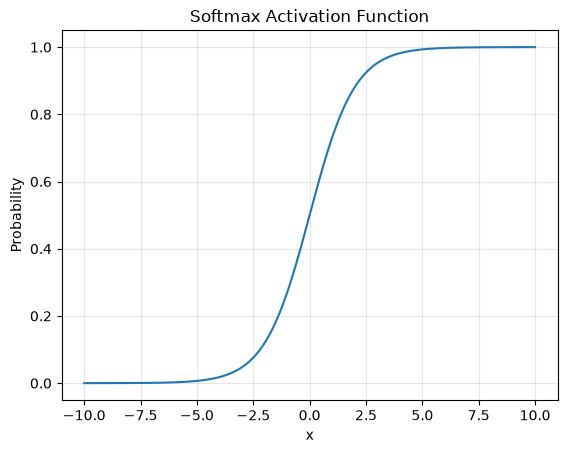

In [9]:
import torch
import matplotlib.pyplot as plt

x = torch.linspace(-10, 10, 500)
inputs_softmax = torch.stack([x, torch.zeros_like(x)], dim=-1)
y = torch.softmax(inputs_softmax, dim=-1)[:, 0]

plt.plot(x.numpy(), y.numpy())
plt.title("Softmax Activation Function")
plt.xlabel("x")
plt.ylabel("Probability")
plt.grid(alpha=0.3) # opacity of grid
plt.show()

In [10]:
x

tensor([-10.0000,  -9.9599,  -9.9198,  -9.8798,  -9.8397,  -9.7996,  -9.7595,
         -9.7194,  -9.6794,  -9.6393,  -9.5992,  -9.5591,  -9.5190,  -9.4790,
         -9.4389,  -9.3988,  -9.3587,  -9.3186,  -9.2786,  -9.2385,  -9.1984,
         -9.1583,  -9.1182,  -9.0782,  -9.0381,  -8.9980,  -8.9579,  -8.9178,
         -8.8778,  -8.8377,  -8.7976,  -8.7575,  -8.7174,  -8.6774,  -8.6373,
         -8.5972,  -8.5571,  -8.5170,  -8.4770,  -8.4369,  -8.3968,  -8.3567,
         -8.3166,  -8.2766,  -8.2365,  -8.1964,  -8.1563,  -8.1162,  -8.0762,
         -8.0361,  -7.9960,  -7.9559,  -7.9158,  -7.8758,  -7.8357,  -7.7956,
         -7.7555,  -7.7154,  -7.6754,  -7.6353,  -7.5952,  -7.5551,  -7.5150,
         -7.4749,  -7.4349,  -7.3948,  -7.3547,  -7.3146,  -7.2745,  -7.2345,
         -7.1944,  -7.1543,  -7.1142,  -7.0741,  -7.0341,  -6.9940,  -6.9539,
         -6.9138,  -6.8737,  -6.8337,  -6.7936,  -6.7535,  -6.7134,  -6.6733,
         -6.6333,  -6.5932,  -6.5531,  -6.5130,  -6.4729,  -6.43

after
```Python
inputs_softmax = torch.stack([x, torch.zeros_like(x)], dim=-1)
```
we get:

In [11]:
inputs_softmax

tensor([[-10.0000,   0.0000],
        [ -9.9599,   0.0000],
        [ -9.9198,   0.0000],
        [ -9.8798,   0.0000],
        [ -9.8397,   0.0000],
        [ -9.7996,   0.0000],
        [ -9.7595,   0.0000],
        [ -9.7194,   0.0000],
        [ -9.6794,   0.0000],
        [ -9.6393,   0.0000],
        [ -9.5992,   0.0000],
        [ -9.5591,   0.0000],
        [ -9.5190,   0.0000],
        [ -9.4790,   0.0000],
        [ -9.4389,   0.0000],
        [ -9.3988,   0.0000],
        [ -9.3587,   0.0000],
        [ -9.3186,   0.0000],
        [ -9.2786,   0.0000],
        [ -9.2385,   0.0000],
        [ -9.1984,   0.0000],
        [ -9.1583,   0.0000],
        [ -9.1182,   0.0000],
        [ -9.0782,   0.0000],
        [ -9.0381,   0.0000],
        [ -8.9980,   0.0000],
        [ -8.9579,   0.0000],
        [ -8.9178,   0.0000],
        [ -8.8778,   0.0000],
        [ -8.8377,   0.0000],
        [ -8.7976,   0.0000],
        [ -8.7575,   0.0000],
        [ -8.7174,   0.0000],
        [ 

After
```Python
y = torch.softmax(inputs, dim=-1)[:, 0]
```
we get

In [12]:
y

tensor([4.5398e-05, 4.7254e-05, 4.9187e-05, 5.1198e-05, 5.3292e-05, 5.5471e-05,
        5.7739e-05, 6.0100e-05, 6.2558e-05, 6.5116e-05, 6.7778e-05, 7.0550e-05,
        7.3435e-05, 7.6438e-05, 7.9563e-05, 8.2817e-05, 8.6203e-05, 8.9728e-05,
        9.3397e-05, 9.7216e-05, 1.0119e-04, 1.0533e-04, 1.0964e-04, 1.1412e-04,
        1.1879e-04, 1.2364e-04, 1.2870e-04, 1.3396e-04, 1.3944e-04, 1.4514e-04,
        1.5107e-04, 1.5725e-04, 1.6368e-04, 1.7037e-04, 1.7734e-04, 1.8459e-04,
        1.9214e-04, 1.9999e-04, 2.0817e-04, 2.1668e-04, 2.2554e-04, 2.3476e-04,
        2.4436e-04, 2.5435e-04, 2.6475e-04, 2.7557e-04, 2.8684e-04, 2.9856e-04,
        3.1077e-04, 3.2347e-04, 3.3670e-04, 3.5046e-04, 3.6479e-04, 3.7970e-04,
        3.9522e-04, 4.1138e-04, 4.2819e-04, 4.4569e-04, 4.6391e-04, 4.8287e-04,
        5.0261e-04, 5.2315e-04, 5.4454e-04, 5.6679e-04, 5.8996e-04, 6.1407e-04,
        6.3916e-04, 6.6529e-04, 6.9247e-04, 7.2077e-04, 7.5022e-04, 7.8088e-04,
        8.1279e-04, 8.4600e-04, 8.8056e-

## 2. Causal Attention

### *We know that...* 

LLMs use all of their **previous and current** tokens to predict the next token, WITHOUT knowing what the future tokens are.

<div class='alert alert-block alert-success'>
Causal attention restricts the model to only consider previous and current inputs in a sequence when processing any given token.
</div>

### Intuition
Use the mask (a lower triangle filled with 1) to multiply by the original attention weights, then normalize using softmax again to get the masked attention weights.

Assume we already got our attention weights.

In [13]:
attn_weights = torch.tensor([[0.1921, 0.1646, 0.1652, 0.1550, 0.1721, 0.1510],
                            [0.2041, 0.1659, 0.1662, 0.1496, 0.1665, 0.1477],
                            [0.2036, 0.1659, 0.1662, 0.1498, 0.1664, 0.1480],
                            [0.1869, 0.1667, 0.1668, 0.1571, 0.1661, 0.1564],
                            [0.1830, 0.1669, 0.1670, 0.1588, 0.1658, 0.1585],
                            [0.1935, 0.1663, 0.1666, 0.1542, 0.1666, 0.1529]],)
context_length = attn_weights.shape[0]
context_length

6

In [14]:
mask = torch.tril(torch.ones(context_length, context_length))
print(mask)

tensor([[1., 0., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0., 0.],
        [1., 1., 1., 0., 0., 0.],
        [1., 1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1., 1.]])


In [15]:
masked = attn_weights * mask

There are actually two ways to normaize this!
#### 1. Probability intuition (Using each element to divide by row sum)

In [16]:
row_sums = masked.sum(dim=1, keepdim=True)
masked_norm = masked / row_sums
print(masked_norm)

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5516, 0.4484, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3801, 0.3097, 0.3102, 0.0000, 0.0000, 0.0000],
        [0.2759, 0.2461, 0.2462, 0.2319, 0.0000, 0.0000],
        [0.2175, 0.1983, 0.1985, 0.1887, 0.1970, 0.0000],
        [0.1935, 0.1663, 0.1666, 0.1542, 0.1666, 0.1529]])


#### 2. Mathematical
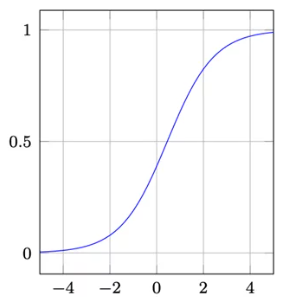

According to the shape of Softmax, -inf for the x coordinate is treated as 0 for the y coordinate.

This time, we assume we already get attention scores.

In [17]:
attn_scores = torch.tensor([[ 0.2899,  0.0716,  0.0760, -0.0138,  0.1344, -0.0511],
                            [ 0.4656,  0.1723,  0.1751,  0.0259,  0.1771,  0.0085],
                            [ 0.4594,  0.1703,  0.1731,  0.0259,  0.1745,  0.0090],
                            [ 0.2642,  0.1024,  0.1036,  0.0186,  0.0973,  0.0122],
                            [ 0.2183,  0.0874,  0.0882,  0.0177,  0.0786,  0.0144],
                            [ 0.3408,  0.1270,  0.1290,  0.0198,  0.1290,  0.0078]])

In [18]:
mask = torch.triu(torch.ones(context_length, context_length), diagonal=1)
# Create tensor that the upper triangle is 1
masked = attn_scores.masked_fill(mask.bool(), -torch.inf)
#Replace 1 with -inf
print(masked)

tensor([[0.2899,   -inf,   -inf,   -inf,   -inf,   -inf],
        [0.4656, 0.1723,   -inf,   -inf,   -inf,   -inf],
        [0.4594, 0.1703, 0.1731,   -inf,   -inf,   -inf],
        [0.2642, 0.1024, 0.1036, 0.0186,   -inf,   -inf],
        [0.2183, 0.0874, 0.0882, 0.0177, 0.0786,   -inf],
        [0.3408, 0.1270, 0.1290, 0.0198, 0.1290, 0.0078]])


Apply Softmax here, and we are done grabbing attention weights.

In [19]:
keys = sa_v2.W_key(inputs)
attn_weights = torch.softmax(masked / keys.shape[-1]**0.5, dim=-1)
# Vanilla softmax usage
print(attn_weights)

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5517, 0.4483, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3800, 0.3097, 0.3103, 0.0000, 0.0000, 0.0000],
        [0.2759, 0.2460, 0.2462, 0.2319, 0.0000, 0.0000],
        [0.2175, 0.1983, 0.1984, 0.1887, 0.1971, 0.0000],
        [0.1935, 0.1663, 0.1666, 0.1542, 0.1666, 0.1529]])


<div class="alert alert-block alert-warning">

Masking in Transformers sets scores for future tokens to a large negative value, making their influence in the softmax calculation effectively zero. 

The softmax function then recalculates attention weights only among the unmasked tokens. 

This process ensures no information leakage from masked tokens, focusing the model solely on the intended data.

</div>

## 2.1 *Tweak!* Dropout

<div class='alert alert-block alert-success'>
Dropout is a deep learning technique where randomly selected hidden layer units are ignored during training.
</div>

### But why?
In fact, in the training process there are many 'lazy neurons' that don't contribute to any of the parameters update, causing a waste of computational power.

Another main reason for dropout is to prevent **overfitting**, that is the model focus on edge cases but not generalize ideas. So definitely **dropout** can be seen as a mean of **regularization**.

In [20]:
torch.manual_seed(123)
dropout = torch.nn.Dropout(0.5) # Dropout rate is 0.5
dropped_out = dropout(attn_weights)
print(dropped_out)

tensor([[2.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.7599, 0.6194, 0.6207, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.4921, 0.4925, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.3966, 0.0000, 0.3775, 0.0000, 0.0000],
        [0.0000, 0.3327, 0.3331, 0.3084, 0.3331, 0.0000]])


In [21]:
batch = torch.stack((inputs, inputs), dim=0)
print(batch.shape) # We stacked two inputs together

torch.Size([2, 6, 3])


<div class="alert alert-block alert-info">

This results in a 3D tensor consisting of 2 input texts with 6 tokens each, where each token
is a 3-dimensional embedding vector.
    
</div>

Notice the dropped out tensor has its surviving element scaled by $\frac{1}{1-\text{dropout rate}}$, otherwise the input will be smaller than expected.

---

Let's put it all together and create a class:

In [22]:
class CausalAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, qkv_bias=False):
        super().__init__()
        self.d_out = d_out
        self.W_query = nn.Linear(d_in, d_out, bias = qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias = qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias = qkv_bias)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer('mask', torch.triu(torch.ones(context_length, context_length), diagonal=1))

    def forward(self, x):
        b, num_tokens, d_in = x.shape
        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)

        attn_scores = queries @ keys.transpose(1,2) # Exchange the position of element 2 and 3 in the shape of Keys matrix
        print(f"Shape of the QKV matrices: {keys.shape}")
        print(f"The shape of the attention score and attention weight: {attn_scores.shape}")
        # The shape of the Q, K, V matrices are (batch_size, num_tokens, d_out)
        # From (batch_size, num_tokens, d_out) to (batch_size, d_out, num_tokens)
        # Multiplication results in attention score with dimension (batch_size, num_tokens, num_tokens)
        attn_scores.masked_fill(
            self.mask.bool()[:num_tokens, :num_tokens], -torch.inf
        )
        attn_weights = torch.softmax(attn_scores/keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)

        context_vec = attn_weights @ values
        return context_vec



The use of `register_buffer` in
PyTorch is not strictly necessary for all use cases but offers several advantages here. 

For
instance, when we use the `CausalAttention` class in our LLM, buffers are automatically
moved to the **appropriate device** (CPU or GPU) along with our model, which will be relevant
when training the LLM.

This means we don't need to manually ensure
these tensors are on the same device as your model parameters, avoiding device mismatch
errors.

In [23]:
torch.manual_seed(123)
context_length = batch.shape[1] # context length / number of tokens is 3
ca = CausalAttention(d_in, d_out, context_length, 0.0)
context_vecs = ca(batch)
print("The shape of Context Vector:", context_vecs.shape) # batch size, context length, output dimensions
print(context_vecs)

Shape of the QKV matrices: torch.Size([2, 6, 2])
The shape of the attention score and attention weight: torch.Size([2, 6, 6])
The shape of Context Vector: torch.Size([2, 6, 2])
tensor([[[-0.5337, -0.1051],
         [-0.5323, -0.1080],
         [-0.5323, -0.1079],
         [-0.5297, -0.1076],
         [-0.5311, -0.1066],
         [-0.5299, -0.1081]],

        [[-0.5337, -0.1051],
         [-0.5323, -0.1080],
         [-0.5323, -0.1079],
         [-0.5297, -0.1076],
         [-0.5311, -0.1066],
         [-0.5299, -0.1081]]], grad_fn=<UnsafeViewBackward0>)


<div class="alert alert-block alert-info">

As we can see, the resulting context vector is a 3D tensor where each token is now represented by a 2D embedding.
    
</div>

## 3. Multi-head attention
In practical terms, implementing multi-head attention involves creating **multiple instances**
of the self-attention mechanism, each with
its own weights, and then combining their outputs

In code, we can achieve this by implementing a simple `MultiHeadAttentionWrapper`
class that **stacks** multiple instances of our previously implemented `CausalAttention`
module:

However, in practice, we implement multi-head attention by **splitting** the query, key, and value matrices for different heads.

### 3.1 Wrapping multiple instances of `CausalAttention`

In [24]:
class MultiHeadAttentionWrapper(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        self.heads = nn.ModuleList(
            [CausalAttention(d_in, d_out, context_length,dropout,qkv_bias)
              for _ in range(num_heads)]
              # Using list comprehension to create num_heads instances of CausalAttention
        )
    def forward(self,x):
        return torch.cat([head(x) for head in self.heads], dim=-1)
        #Sequentially call the forward method (i.e., head(x)) of each CausalAttention submodule in self.heads
        #resulting shape (batch_size, seq_len, d_out) (the output of each head)
        
        #torch.cat(..., dim=-1): Concatenate the outputs of these heads along the last dimension (feature dimension)
        #producing a tensor with shape (batch_size, seq_len, num_heads * d_out).


In [25]:
torch.manual_seed(123)
mha = MultiHeadAttentionWrapper(d_in, d_out, context_length, 0.0, num_heads=2)
context_vecs = mha(batch)
print(context_vecs)
print("context_vecs.shape()", context_vecs.shape)

Shape of the QKV matrices: torch.Size([2, 6, 2])
The shape of the attention score and attention weight: torch.Size([2, 6, 6])
Shape of the QKV matrices: torch.Size([2, 6, 2])
The shape of the attention score and attention weight: torch.Size([2, 6, 6])
tensor([[[-0.5337, -0.1051,  0.5085,  0.3508],
         [-0.5323, -0.1080,  0.5084,  0.3508],
         [-0.5323, -0.1079,  0.5084,  0.3506],
         [-0.5297, -0.1076,  0.5074,  0.3471],
         [-0.5311, -0.1066,  0.5076,  0.3446],
         [-0.5299, -0.1081,  0.5077,  0.3493]],

        [[-0.5337, -0.1051,  0.5085,  0.3508],
         [-0.5323, -0.1080,  0.5084,  0.3508],
         [-0.5323, -0.1079,  0.5084,  0.3506],
         [-0.5297, -0.1076,  0.5074,  0.3471],
         [-0.5311, -0.1066,  0.5076,  0.3446],
         [-0.5299, -0.1081,  0.5077,  0.3493]]], grad_fn=<CatBackward0>)
context_vecs.shape() torch.Size([2, 6, 4])


- The first dimension of the resulting context_vecs tensor is 2 since we have two input texts
(the input texts are duplicated, which is why the context vectors are exactly the same for
those). 

- The second dimension refers to the 6 tokens in each input. 

- The third dimension
refers to the 4-dimensional embedding of each token.

Note that these single-head attention heads are processed sequentially via
`[head(x) for head in self.heads]` in the forward method. 

We can improve this
implementation by processing the heads **in parallel**. 

One way to achieve this is by
computing the outputs for all attention heads simultaneously.

### 3.2 Multi-head attention class

As you can see, it is possible to concatenate multiple causal attention to form a multihead attention.

However, it is noteworthy that only **one** multihead attention class can include all functionalities needed.

It **splits** the input into multiple heads by reshaping the projected `query`, `key`, and `value` tensors and then **combines** the results from these heads after computing attention.

In [26]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert (d_out % num_heads == 0), \
            "d_out must be divisible by num_heads"
        
        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads # Reduce the projection dim to match the desired output dim
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out) # Linear layer to combine head inputs
        self.dropout = nn.Dropout(dropout) # Floor division
        self.register_buffer(
            "mask",
            torch.triu(torch.ones(context_length, context_length), diagonal = 1)
        )

    def forward(self, x):
        b, num_tokens, d_in = x.shape

        keys = self.W_key(x) # Shape: (b, num_tokens, d_out)
        queries = self.W_key(x)
        values = self.W_value(x)

        # We implicitly split the matrix by adding a 'num_heads' dimension
        # Unroll the last dim: (b, num_tokens, d_out) -> (b, num_tokens, num_heads, head_dim)
        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim)
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)

        # Transpose: (b, num_tokens, num_heads, head_dim) -> (b, num_heads, num_tokens, head_dim)
        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)

        # Compute scaled dot-product attention (self-attention) with a causal mask
        attn_scores = queries @ keys.transpose(2, 3) # Dot product for each head
        # (b, num_heads, num_tokens, num_tokens)

        attn_scores.masked_fill_(self.mask.bool()[:num_tokens, :num_tokens], -torch.inf)
        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)

        # Shape: (b, num_tokens, num_heads, head_dim)
        context_vec = (attn_weights @ values).transpose(1,2)

        # Combine heads, where self.d_out = self.num_heads * self.head_dim
        context_vec = context_vec.contiguous().view(b, num_tokens, self.d_out)
        context_vec = self.out_proj(context_vec)
        # Combine all heads back into one unified representation.

        return context_vec



### **Clarifications**

#### Spliting

 achieved using the `.view` method: a
tensor of dimensions `(b, num_tokens, d_out)` is reshaped to dimension `(b, num_tokens, num_heads, head_dim)`.

#### Efficiency
Even though the `MultiHeadAttention` class looks more complicated than the
`MultiHeadAttentionWrapper` due to the additional reshaping and transposition of tensors,
it is more **efficient**. 

The reason is that we only need **one** matrix multiplication to compute
the keys, for instance, ``keys = self.W_key(x)`` (the same is true for the queries and values). 
                                              

In the `MultiHeadAttentionWrapper`, we needed to **repeat** this matrix multiplication,
which is computationally one of the most expensive steps, for each attention head.

In [27]:
torch.manual_seed(123)

# Define the tensor with 3 rows and 6 columns
inputs = torch.tensor(
    [[0.43, 0.15, 0.89, 0.55, 0.87, 0.66],  # Row 1
     [0.57, 0.85, 0.64, 0.22, 0.58, 0.33],  # Row 2
     [0.77, 0.25, 0.10, 0.05, 0.80, 0.55]]  # Row 3
)

batch = torch.stack((inputs, inputs), dim=0)
print(batch.shape) 

batch_size, context_length, d_in = batch.shape
d_out = 6
mha = MultiHeadAttention(d_in, d_out, context_length, 0.0, num_heads=2)
context_vecs = mha(batch)
print(context_vecs)
print("context_vecs.shape:", context_vecs.shape)

torch.Size([2, 3, 6])
tensor([[[ 0.1569, -0.0873,  0.0210,  0.0215, -0.3243, -0.2518],
         [ 0.1071, -0.0514,  0.0424, -0.0255, -0.3252, -0.3040],
         [ 0.1175, -0.0481,  0.0330, -0.0632, -0.2811, -0.2616]],

        [[ 0.1569, -0.0873,  0.0210,  0.0215, -0.3243, -0.2518],
         [ 0.1071, -0.0514,  0.0424, -0.0255, -0.3252, -0.3040],
         [ 0.1175, -0.0481,  0.0330, -0.0632, -0.2811, -0.2616]]],
       grad_fn=<ViewBackward0>)
context_vecs.shape: torch.Size([2, 3, 6])
